 # Machine Learning Assignment 2

Student Name --Rashmi Prashant Sushir

BITS ID-- 2026AK05082

### Project Summery
This Project Performs binary classification using the "Breast Cancer Wisconsin (Diagnostic)" 
Dataset.This Dataset contains '569 samples and 30 numerical features,with two target classes:malignant and benign. Five machine-learning algorithms are implemented and compared: Logistic Regression, Decision Tree, K-Nearest Neighbors,Guassian Naive Bayes and Support Vector Machine(SVM). the models are evaluated using Accuracy, AUC, Precision, Recall, F1 Score,and Matthews Correlation Coefficient (MCC score).The trained models saved and integrated into a Streamlit application for prediction and model comparison 

!pip install numpy pandas matplotlib seaborn joblib scikit-learn

### Import Libraries

In [8]:
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
   accuracy_score,
   roc_auc_score,
   precision_score,
   recall_score,
   f1_score,
   matthews_corrcoef,
   confusion_matrix,
   classification_report
)
print("scikit-learn version:", sklearn.__version__)
print("All required libraries imported successfully.")



scikit-learn version: 1.9.1
All required libraries imported successfully.


In [9]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
svm = SVC()
models = {
   "Logistic Regression": LogisticRegression(),
   "Decision Tree": DecisionTreeClassifier(),
   "K-Nearest Neighbors": KNeighborsClassifier(),
   "Gaussian Naive Bayes": GaussianNB(),
   "Support Vector Machine": CalibratedClassifierCV(
       svm,
       ensemble=False
   )
}

In [10]:
import warnings

warnings.filterwarnings("ignore")
 

In [11]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
print("Dataset shape:", X.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", data.target_names)
display(X.head())

Dataset shape: (569, 30)
Number of samples: 569
Number of features: 30
Target classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify= y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


### Data Cleaning and Validation

The dataset is checked for missing values, duplicate records ,class distribution and data types before model training.

In [14]:
print("Missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
print("\nClass distribution:")
print(y.value_counts())
print("\nData types:")
print(X.dtypes.value_counts())

Missing values: 0
Duplicate rows: 0

Class distribution:
target
1    357
0    212
Name: count, dtype: int64

Data types:
float64    30
Name: count, dtype: int64


### Model Building

#### Five Classification algorithms are trained and compared: 

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Guassian Naive Bayes
5. Support Vector Machine(SVM)


In [16]:
models = {
   "Logistic Regression": Pipeline([
       ("scaler", StandardScaler()),
       ("classifier", LogisticRegression(
           max_iter=5000,
           random_state=42
       ))
   ]),
   "Decision Tree": Pipeline([
       ("classifier", DecisionTreeClassifier(
           max_depth=5,
           min_samples_split=4,
           random_state=42
       ))
   ]),
   "K-Nearest Neighbors": Pipeline([
       ("scaler", StandardScaler()),
       ("classifier", KNeighborsClassifier(
           n_neighbors=5
       ))
   ]),
   "Gaussian Naive Bayes": Pipeline([
       ("classifier", GaussianNB())
   ]),
   "Support Vector Machine": Pipeline([
       ("scaler", StandardScaler()),
       ("classifier", SVC(
           kernel="rbf",
           probability=True,
           random_state=42
       ))
   ])
}
print("Models created successfully.")
for name in models:
   print(name)

Models created successfully.
Logistic Regression
Decision Tree
K-Nearest Neighbors
Gaussian Naive Bayes
Support Vector Machine


### Create the evaluation function

Evaluation Metrices

Each model is evaluated using Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC).

In [18]:
def calculate_metrics(y_true, y_pred, y_prob):
   return {
       "Accuracy": accuracy_score(y_true, y_pred),
       "AUC": roc_auc_score(y_true, y_prob),
       "Precision": precision_score(
           y_true, y_pred, zero_division=0
       ),
       "Recall": recall_score(
           y_true, y_pred, zero_division=0
       ),
       "F1": f1_score(
           y_true, y_pred, zero_division=0
       ),
       "MCC": matthews_corrcoef(
           y_true, y_pred
       )
   }
print("Metric function created successfully.")

Metric function created successfully.


### Model training and Prediction

In [20]:
results = []
for model_name, model in models.items():
   # Train model using training data
   model.fit(X_train, y_train)
   # Predict classes
   y_pred = model.predict(X_test)
   # Probability for class 1
   y_prob = model.predict_proba(X_test)[:, 1]
   # Calculate evaluation metrics
   metrics = calculate_metrics(
       y_test,
       y_pred,
       y_prob
   )
   results.append({
       "Model": model_name,
       **metrics
   })
   print(model_name, "completed")

Logistic Regression completed
Decision Tree completed
K-Nearest Neighbors completed
Gaussian Naive Bayes completed
Support Vector Machine completed


### Model Performance Comparison

In [22]:
results_df = pd.DataFrame(results)
display(
   results_df.style.format({
       "Accuracy": "{:.4f}",
       "AUC": "{:.4f}",
       "Precision": "{:.4f}",
       "Recall": "{:.4f}",
       "F1": "{:.4f}",
       "MCC": "{:.4f}"
   })
)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9211,0.9163,0.9565,0.9167,0.9362,0.8341
2,K-Nearest Neighbors,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Gaussian Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


In [23]:
best_model_row = results_df.loc[
   results_df["F1"].idxmax()
]
print("Best Model based on F1 Score:")
print(best_model_row)


Best Model based on F1 Score:
Model        Logistic Regression
Accuracy                0.982456
AUC                      0.99537
Precision               0.986111
Recall                  0.986111
F1                      0.986111
MCC                     0.962302
Name: 0, dtype: object


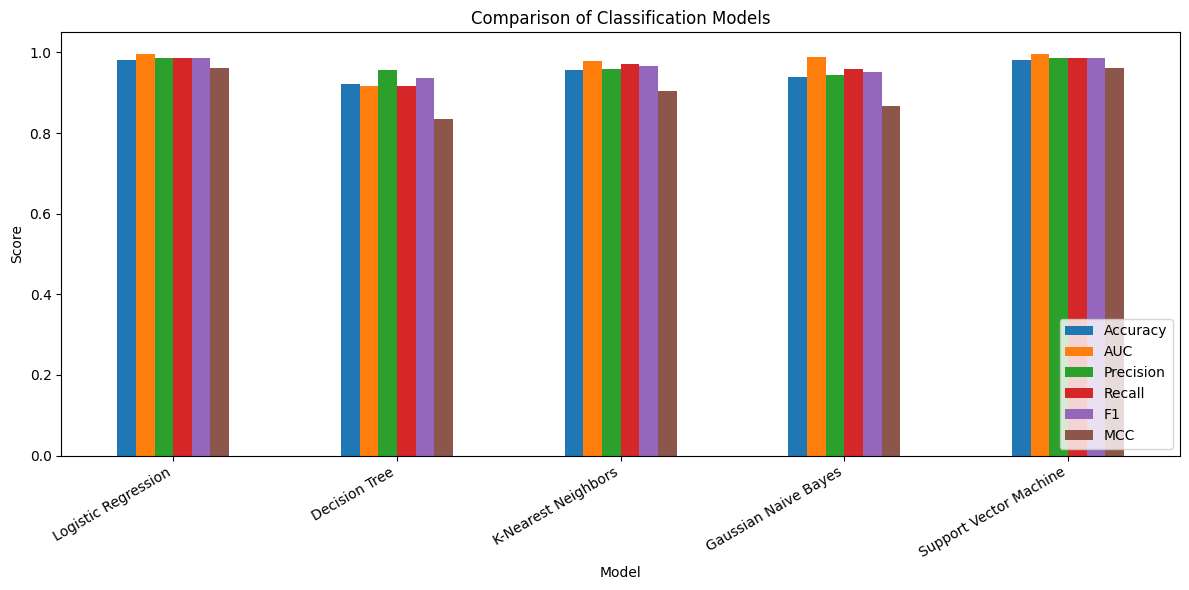

In [24]:
plot_data = results_df.set_index("Model")
plot_data.plot(
   kind="bar",
   figsize=(12, 6)
)
plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Confusion Matrices

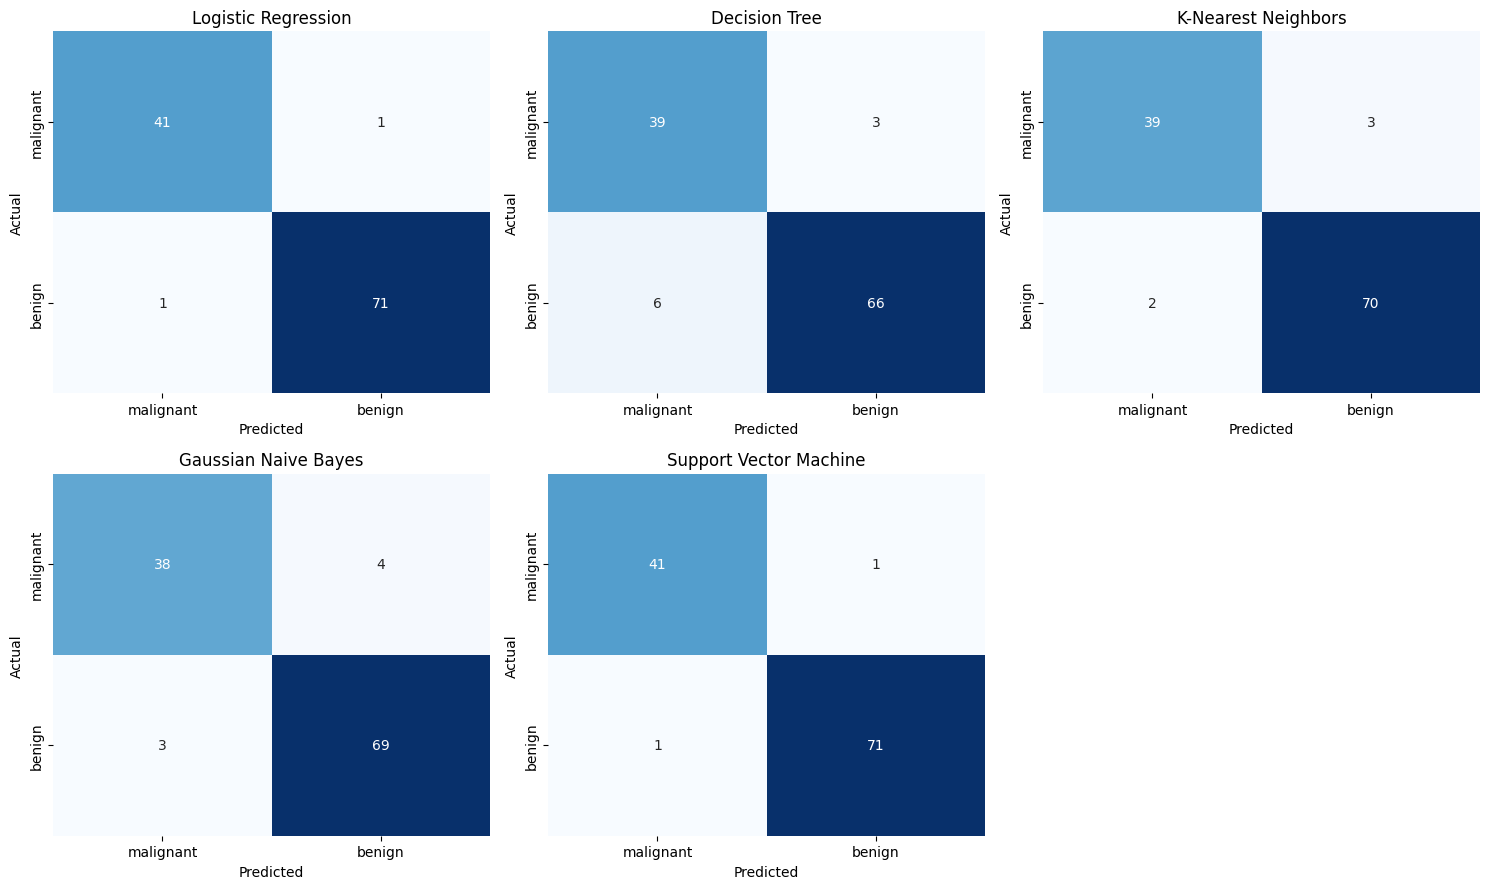

In [26]:

fig, axes = plt.subplots(
   2,
   3,
   figsize=(15, 9)
)
axes = axes.flatten()
for i, (model_name, model) in enumerate(models.items()):
   y_pred = model.predict(X_test)
   cm = confusion_matrix(
       y_test,
       y_pred
   )
   sns.heatmap(
       cm,
       annot=True,
       fmt="d",
       cmap="Blues",
       cbar=False,
       ax=axes[i],
       xticklabels=data.target_names,
       yticklabels=data.target_names
   )
   axes[i].set_title(model_name)
   axes[i].set_xlabel("Predicted")
   axes[i].set_ylabel("Actual")
# Remove unused sixth subplot
axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [27]:
for model_name, model in models.items():
   print("=" * 60)
   print(model_name)
   print("=" * 60)
   y_pred = model.predict(X_test)
   print(
       classification_report(
           y_test,
           y_pred,
           target_names=data.target_names
       )
   )

Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Decision Tree
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114

K-Nearest Neighbors
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0

In [28]:
test_data = X_test.copy()
test_data["target"] = y_test.to_numpy()
test_data.to_csv(
   "test_data.csv",
   index=False
)
print("test_data.csv created successfully.")
print("Shape:", test_data.shape)
display(test_data.head())

test_data.csv created successfully.
Shape: (114, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
256,19.55,28.77,133.60,1207.0,0.09260,0.20630,0.17840,0.11440,0.1893,0.06232,...,36.27,178.60,1926.0,0.1281,0.53290,0.4251,0.19410,0.2818,0.10050,0
428,11.13,16.62,70.47,381.1,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,...,20.29,74.35,421.1,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083,1
501,13.82,24.49,92.33,595.9,0.11620,0.16810,0.13570,0.06759,0.2275,0.07237,...,32.94,106.00,788.0,0.1794,0.39660,0.3381,0.15210,0.3651,0.11830,0
363,16.50,18.29,106.60,838.1,0.09686,0.08468,0.05862,0.04835,0.1495,0.05593,...,25.45,117.20,1009.0,0.1338,0.16790,0.1663,0.09123,0.2394,0.06469,1
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.1410,0.21130,0.4107,0.22160,0.2060,0.07115,0


In [29]:
results_df.to_csv(
   "model_metrics.csv",
   index=False
)
print("model_metrics.csv saved successfully.")

model_metrics.csv saved successfully.


In [30]:
results_df.to_csv(
   "model_metrics.csv",
   index=False
)
print("model_metrics.csv saved successfully.")

import os
import joblib
os.makedirs(
   "models",
   exist_ok=True
)
model_files = {
   "Logistic Regression":
       "logistic_regression.joblib",
   "Decision Tree":
       "decision_tree.joblib",
   "K-Nearest Neighbors":
       "knn.joblib",
   "Gaussian Naive Bayes":
       "naive_bayes.joblib",
   "Support Vector Machine":
       "svm.joblib"
}
for model_name, model in models.items():
   path = os.path.join(
       "models",
       model_files[model_name]
   )
   joblib.dump(model, path)
   print("Saved:", path)



model_metrics.csv saved successfully.
Saved: models/logistic_regression.joblib
Saved: models/decision_tree.joblib
Saved: models/knn.joblib
Saved: models/naive_bayes.joblib
Saved: models/svm.joblib


In [31]:
for model_name, filename in model_files.items():
   loaded_model = joblib.load(
       os.path.join("models", filename)
   )
   predictions = loaded_model.predict(
       X_test.head(5)
   )
   print(
       model_name,
       "->",
       predictions
   )
for model_name, filename in model_files.items():
   loaded_model = joblib.load(
       os.path.join("models", filename)
   )
   predictions = loaded_model.predict(
       X_test.head(5)
   )
   print(
       model_name,
       "->",
       predictions
   )

Logistic Regression -> [0 1 0 1 0]
Decision Tree -> [0 1 0 1 0]
K-Nearest Neighbors -> [0 1 0 0 0]
Gaussian Naive Bayes -> [0 1 0 1 0]
Support Vector Machine -> [0 1 0 1 0]
Logistic Regression -> [0 1 0 1 0]
Decision Tree -> [0 1 0 1 0]
K-Nearest Neighbors -> [0 1 0 0 0]
Gaussian Naive Bayes -> [0 1 0 1 0]
Support Vector Machine -> [0 1 0 1 0]


In [32]:
print("Project files:")
for file in os.listdir("."):
   print(file)

Project files:
app.py
models
.ipynb_checkpoints
model_metrics.csv
2026ak05082.ipynb
test_data.csv


In [33]:
print("Saved models:")
for file in os.listdir("models"):
   print(file)


Saved models:
svm.joblib
naive_bayes.joblib
logistic_regression.joblib
decision_tree.joblib
knn.joblib


## Conclusion


Five machine-learning classification algorithms were trained and evaluated
using the Breast Cancer Wisconsin Diagnostic dataset. Performance was
compared using Accuracy, AUC, Precision, Recall, F1 Score and Matthews
Correlation Coefficient.

%%writefile app.py

import os
import joblib
import pandas as pd
import streamlit as st

from sklearn.metrics import (

   accuracy_score,

   roc_auc_score,

   precision_score,

   recall_score,

   f1_score,

   matthews_corrcoef,

   confusion_matrix,

   classification_report

)
 
# ============================================================

# PROJECT PATHS

# ============================================================

# Folder containing app.py

BASE_DIR = Path(__file__).resolve().parent

# Folder containing saved models

MODEL_DIR = BASE_DIR / "models"

# Other project files

TEST_DATA_FILE = BASE_DIR / "test_data.csv"

METRICS_FILE = BASE_DIR / "model_metrics.csv"
 
# ============================================================

# PAGE CONFIGURATION

# ============================================================

st.set_page_config(

   page_title="ML Assignment 2",

   page_icon="🔬",

   layout="wide"

)

st.title("Machine Learning Assignment 2")

st.subheader(

   "Breast Cancer Wisconsin Diagnostic Classification"

)

st.write(

   "Upload the test dataset and select one of the five "

   "trained machine learning models to evaluate its performance."

)

st.warning(

   "This application is for educational purposes only "

   "and is not intended for medical diagnosis."

)
 
# ============================================================

# SAVED MODEL FILES

# ============================================================

model_files = {

   "Logistic Regression":

       MODEL_DIR / "logistic_regression.joblib",

   "Decision Tree":

       MODEL_DIR / "decision_tree.joblib",

   "K-Nearest Neighbors":

       MODEL_DIR / "knn.joblib",

   "Gaussian Naive Bayes":

       MODEL_DIR / "naive_bayes.joblib",

   "Support Vector Machine":

       MODEL_DIR / "svm.joblib"

}
 
# ============================================================

# SIDEBAR

# ============================================================

st.sidebar.header("Model Evaluation")

selected_model = st.sidebar.selectbox(

   "Select Machine Learning Model",

   list(model_files.keys())

)

uploaded_file = st.sidebar.file_uploader(

   "Upload Test CSV File",

   type=["csv"]

)
 
# ============================================================

# SAMPLE TEST DATA DOWNLOAD

# ============================================================

if TEST_DATA_FILE.exists():

   with open(TEST_DATA_FILE, "rb") as file:

       st.sidebar.download_button(

           label="Download Sample Test Data",

           data=file,

           file_name="test_data.csv",

           mime="text/csv"

       )
 
# ============================================================

# PROCESS UPLOADED FILE

# ============================================================

if uploaded_file is not None:

   try:

       # ----------------------------------------------------

       # READ TEST DATA

       # ----------------------------------------------------

       test_data = pd.read_csv(uploaded_file)

       st.subheader("Uploaded Test Dataset")

       col1, col2 = st.columns(2)

       col1.metric(

           "Number of Rows",

           test_data.shape[0]

       )

       col2.metric(

           "Number of Columns",

           test_data.shape[1]

       )

       st.dataframe(

           test_data.head(10),

           use_container_width=True

       )
 
       # ----------------------------------------------------

       # VALIDATE TARGET COLUMN

       # ----------------------------------------------------

       if "target" not in test_data.columns:

           st.error(

               "The uploaded CSV must contain "

               "a column named 'target'."

           )

           st.stop()
 
       # ----------------------------------------------------

       # SEPARATE FEATURES AND TARGET

       # ----------------------------------------------------

       X_test = test_data.drop(

           columns=["target"]

       )

       y_test = test_data["target"]
 
       # ----------------------------------------------------

       # LOAD SELECTED MODEL

       # ----------------------------------------------------

       model_path = model_files[selected_model]

       if not model_path.exists():

           st.error(

               f"Model file not found: {model_path}"

           )

           st.stop()

       model = joblib.load(model_path)
 
       # ----------------------------------------------------

       # PREDICTIONS

       # ----------------------------------------------------

       y_pred = model.predict(X_test)

       y_probability = model.predict_proba(

           X_test

       )[:, 1]
 
       # ----------------------------------------------------

       # CALCULATE REQUIRED METRICS

       # ----------------------------------------------------

       accuracy = accuracy_score(

           y_test,

           y_pred

       )

       auc = roc_auc_score(

           y_test,

           y_probability

       )

       precision = precision_score(

           y_test,

           y_pred,

           zero_division=0

       )

       recall = recall_score(

           y_test,

           y_pred,

           zero_division=0

       )

       f1 = f1_score(

           y_test,

           y_pred,

           zero_division=0

       )

       mcc = matthews_corrcoef(

           y_test,

           y_pred

       )
 
       # ----------------------------------------------------

       # SUCCESS MESSAGE

       # ----------------------------------------------------

       st.success(

           f"Model evaluated successfully: {selected_model}"

       )
 
       # ----------------------------------------------------

       # DISPLAY SIX METRICS

       # ----------------------------------------------------

       st.subheader("Evaluation Metrics")

       col1, col2, col3 = st.columns(3)

       col1.metric(

           "Accuracy",

           f"{accuracy:.4f}"

       )

       col2.metric(

           "AUC",

           f"{auc:.4f}"

       )

       col3.metric(

           "Precision",

           f"{precision:.4f}"

       )

       col4, col5, col6 = st.columns(3)

       col4.metric(

           "Recall",

           f"{recall:.4f}"

       )

       col5.metric(

           "F1 Score",

           f"{f1:.4f}"

       )

       col6.metric(

           "MCC",

           f"{mcc:.4f}"

       )
 
       # ----------------------------------------------------

       # CONFUSION MATRIX

       # ----------------------------------------------------

       st.subheader("Confusion Matrix")

       cm = confusion_matrix(

           y_test,

           y_pred,

           labels=[0, 1]

       )

       confusion_df = pd.DataFrame(

           cm,

           index=[

               "Actual Malignant",

               "Actual Benign"

           ],

           columns=[

               "Predicted Malignant",

               "Predicted Benign"

           ]

       )

       st.dataframe(

           confusion_df,

           use_container_width=True

       )
 
       # ----------------------------------------------------

       # CLASSIFICATION REPORT

       # ----------------------------------------------------

       st.subheader("Classification Report")

       report = classification_report(

           y_test,

           y_pred,

           labels=[0, 1],

           target_names=[

               "Malignant",

               "Benign"

           ],

           output_dict=True,

           zero_division=0

       )

       report_df = pd.DataFrame(

           report

       ).transpose()

       st.dataframe(

           report_df.style.format("{:.4f}"),

           use_container_width=True

       )
 
       # ----------------------------------------------------

       # PREDICTION RESULTS

       # ----------------------------------------------------

       st.subheader("Prediction Results")

       prediction_results = test_data.copy()

       prediction_results["prediction"] = y_pred

       prediction_results["prediction_label"] = [

           "Benign" if value == 1

           else "Malignant"

           for value in y_pred

       ]

       prediction_results[

           "benign_probability"

       ] = y_probability

       st.dataframe(

           prediction_results.head(20),

           use_container_width=True

       )
 
       # ----------------------------------------------------

       # DOWNLOAD PREDICTIONS

       # ----------------------------------------------------

       csv_output = (

           prediction_results

           .to_csv(index=False)

           .encode("utf-8")

       )

       st.download_button(

           label="Download Prediction Results",

           data=csv_output,

           file_name="predictions.csv",

           mime="text/csv"

       )
 
   except Exception as error:

       st.error(

           f"Unable to evaluate uploaded data: {error}"

       )
 
      # ============================================================

      # BEFORE TEST DATA IS UPLOADED

      # ============================================================

else:
 
    st.info(

	       "Please upload test_data.csv from the sidebar "

	       "to evaluate a trained model."

	   )
 
   # --------------------------------------------------------

   # DISPLAY SAVED MODEL METRICS

   # --------------------------------------------------------

    if METRICS_FILE.exists():

        st.subheader(

           "Model Performance Comparison"

       )

       metrics_df = pd.read_csv(

           METRICS_FILE

       )

       metric_columns = [

           "Accuracy",

           "AUC",

           "Precision",

           "Recall",

           "F1",

           "MCC"

       ]

       format_dictionary = {

           column: "{:.4f}"

           for column in metric_columns

           if column in metrics_df.columns

       }

       st.dataframe(

           metrics_df.style.format(

               format_dictionary

           ),

           use_container_width=True

       )
 
# ============================================================

# PROJECT INFORMATION

# ============================================================

st.divider()

st.subheader("Models Implemented")

st.markdown(

   """

1. Logistic Regression

2. Decision Tree Classifier

3. K-Nearest Neighbors

4. Gaussian Naive Bayes

5. Support Vector Machine

"""

)
 
from pathlib import Path

import joblib

import pandas as pd

import streamlit as st

from sklearn.metrics import (

    accuracy_score,

    roc_auc_score,

    precision_score,

    recall_score,

    f1_score,

    matthews_corrcoef,

    confusion_matrix,

    classification_report

)

# ============================================================

# PROJECT PATHS

# ============================================================

BASE_DIR = Path(__file__).resolve().parent

MODEL_DIR = BASE_DIR / "models"

TEST_DATA_FILE = BASE_DIR / "test_data.csv"

METRICS_FILE = BASE_DIR / "model_metrics.csv"

# ============================================================

# PAGE CONFIGURATION

# ============================================================

st.set_page_config(

    page_title="ML Assignment 2",

    page_icon="🔬",

    layout="wide"

)

st.title("Machine Learning Assignment 2")

st.subheader(

    "Breast Cancer Wisconsin Diagnostic Classification"

)

st.write(

    "Upload the test dataset and select one of the five "

    "trained machine learning models to evaluate its performance."

)

st.warning(

    "This application is for educational purposes only "

    "and is not intended for medical diagnosis."

)

# ============================================================

# SAVED MODEL FILES

# ============================================================

model_files = {

    "Logistic Regression":

        MODEL_DIR / "logistic_regression.joblib",

    "Decision Tree":

        MODEL_DIR / "decision_tree.joblib",

    "K-Nearest Neighbors":

        MODEL_DIR / "knn.joblib",

    "Gaussian Naive Bayes":

        MODEL_DIR / "naive_bayes.joblib",

    "Support Vector Machine":

        MODEL_DIR / "svm.joblib"

}

# ============================================================

# SIDEBAR

# ============================================================

st.sidebar.header("Model Evaluation")

selected_model = st.sidebar.selectbox(

    "Select Machine Learning Model",

    list(model_files.keys())

)

uploaded_file = st.sidebar.file_uploader(

    "Upload Test CSV File",

    type=["csv"]

)

# ============================================================

# SAMPLE TEST DATA DOWNLOAD

# ============================================================

if TEST_DATA_FILE.exists():

    with open(TEST_DATA_FILE, "rb") as file:

        st.sidebar.download_button(

            label="Download Sample Test Data",

            data=file,

            file_name="test_data.csv",

            mime="text/csv"

        )

# ============================================================

# PROCESS UPLOADED FILE

# ============================================================

if uploaded_file is not None:

    try:

        # ----------------------------------------------------

        # READ TEST DATA

        # ----------------------------------------------------

        test_data = pd.read_csv(uploaded_file)

        st.subheader("Uploaded Test Dataset")

        col1, col2 = st.columns(2)

        col1.metric(

            "Number of Rows",

            test_data.shape[0]

        )

        col2.metric(

            "Number of Columns",

            test_data.shape[1]

        )

        st.dataframe(

            test_data.head(10),

            use_container_width=True

        )

        # ----------------------------------------------------

        # VALIDATE TARGET COLUMN

        # ----------------------------------------------------

        if "target" not in test_data.columns:

            st.error(

                "The uploaded CSV must contain a column named 'target'."

            )

            st.stop()

        # ----------------------------------------------------

        # SEPARATE FEATURES AND TARGET

        # ----------------------------------------------------

        X_test = test_data.drop(columns=["target"])

        y_test = test_data["target"]

        # ----------------------------------------------------

        # LOAD MODEL

        # ----------------------------------------------------

        model_path = model_files[selected_model]

        if not model_path.exists():

            st.error(

                f"Model file not found: {model_path}"

            )

            st.stop()

        model = joblib.load(model_path)

        # ----------------------------------------------------

        # PREDICTIONS

        # ----------------------------------------------------

        y_pred = model.predict(X_test)

        if hasattr(model, "predict_proba"):

            y_probability = model.predict_proba(X_test)[:, 1]

        else:

            y_probability = model.decision_function(X_test)

        # ----------------------------------------------------

        # METRICS

        # ----------------------------------------------------

        accuracy = accuracy_score(

            y_test,

            y_pred

        )

        auc = roc_auc_score(

            y_test,

            y_probability

        )

        precision = precision_score(

            y_test,

            y_pred,

            zero_division=0

        )

        recall = recall_score(

            y_test,

            y_pred,

            zero_division=0

        )

        f1 = f1_score(

            y_test,

            y_pred,

            zero_division=0

        )

        mcc = matthews_corrcoef(

            y_test,

            y_pred

        )

        st.success(

            f"Model evaluated successfully: {selected_model}"

        )

        # ----------------------------------------------------

        # DISPLAY METRICS

        # ----------------------------------------------------

        st.subheader("Evaluation Metrics")

        col1, col2, col3 = st.columns(3)

        col1.metric(

            "Accuracy",

            f"{accuracy:.4f}"

        )

        col2.metric(

            "AUC",

            f"{auc:.4f}"

        )

        col3.metric(

            "Precision",

            f"{precision:.4f}"

        )

        col4, col5, col6 = st.columns(3)

        col4.metric(

            "Recall",

            f"{recall:.4f}"

        )

        col5.metric(

            "F1 Score",

            f"{f1:.4f}"

        )

        col6.metric(

            "MCC",

            f"{mcc:.4f}"

        )

        # ----------------------------------------------------

        # CONFUSION MATRIX

        # ----------------------------------------------------

        st.subheader("Confusion Matrix")

        cm = confusion_matrix(

            y_test,

            y_pred,

            labels=[0, 1]

        )

        confusion_df = pd.DataFrame(

            cm,

            index=[

                "Actual 0 (Malignant)",

                "Actual 1 (Benign)"

            ],

            columns=[

                "Predicted 0 (Malignant)",

                "Predicted 1 (Benign)"

            ]

        )

        st.dataframe(

            confusion_df,

            use_container_width=True

        )

        # ----------------------------------------------------

        # CLASSIFICATION REPORT

        # ----------------------------------------------------

        st.subheader("Classification Report")

        report = classification_report(

            y_test,

            y_pred,

            labels=[0, 1],

            target_names=[

                "Malignant",

                "Benign"

            ],

            output_dict=True,

            zero_division=0

        )

        report_df = pd.DataFrame(report).transpose()

        st.dataframe(

            report_df.style.format("{:.4f}"),

            use_container_width=True

        )

        # ----------------------------------------------------

        # PREDICTION RESULTS

        # ----------------------------------------------------

        st.subheader("Prediction Results")

        prediction_results = test_data.copy()

        prediction_results["prediction"] = y_pred

        prediction_results["prediction_label"] = [

            "Benign" if value == 1 else "Malignant"

            for value in y_pred

        ]

        prediction_results[

            "benign_probability"

        ] = y_probability

        st.dataframe(

            prediction_results.head(20),

            use_container_width=True

        )

        # ----------------------------------------------------

        # DOWNLOAD PREDICTIONS

        # ----------------------------------------------------

        csv_output = (

            prediction_results

            .to_csv(index=False)

            .encode("utf-8")

        )

        st.download_button(

            label="Download Prediction Results",

            data=csv_output,

            file_name="predictions.csv",

            mime="text/csv"

        )

    except Exception as error:

        st.error(

            f"Unable to evaluate uploaded data: {error}"

        )

# ============================================================

# BEFORE TEST DATA IS UPLOADED

# ============================================================

else:
st.info(

        "Please upload test_data.csv from the sidebar "

        "to evaluate a trained model."

    )

    # --------------------------------------------------------

    # DISPLAY SAVED MODEL METRICS

    # --------------------------------------------------------

    if METRICS_FILE.exists():

        st.subheader(

            "Model Performance Comparison"

        )

        metrics_df = pd.read_csv(

            METRICS_FILE

        )

        metric_columns = [

            "Accuracy",

            "AUC",

            "Precision",

            "Recall",

            "F1",

            "MCC"

        ]

        format_dictionary = {

            column: "{:.4f}"

            for column in metric_columns

            if column in metrics_df.columns

        }

        st.dataframe(

            metrics_df.style.format(

                format_dictionary

            ),

            use_container_width=True

        )

# ============================================================

# PROJECT INFORMATION

# ============================================================

st.divider()

st.subheader("Models Implemented")

st.markdown(

    """

1. Logistic Regression

2. Decision Tree Classifier

3. K-Nearest Neighbors

4. Gaussian Naive Bayes

5. Support Vector Machine

"""

)

